# The Price of Autonomy: replication notebook
**Accuracy, cost and time trade-offs of LLM agents building a predictive model**
Owen Chong | CSCI E-89 Deep Learning, Harvard Extension School | Fall 2026

## What this study asked
Autonomous LLM agents can plan, write and run code on their own, and vendors charge per token and sell a "reasoning effort" setting. If a manager lets an agent do a data scientist's job alone, *what does the agent deliver, and what does it cost?*
The task was a realistic one: predict, **at the moment a hotel booking is created**, whether it will end in a cancellation or a no-show (an **"at-risk"** booking), so that revenue staff can plan overbooking, deposits and reminders.

* **6 hosted models** (Anthropic Claude Haiku, Sonnet, Opus; OpenAI GPT Luna, Terra, Sol), each at **3 reasoning-effort levels**, **3 replicates** each = **54 runs**; plus 6 runs of a small local model (Google Gemma 4).
* Every agent received the *same* short brief and the *same* raw training data, and had to deliver a prediction script (`predict.py`), a saved model and a notes file.
* An **independent evaluator** scored every deliverable on a hidden, later test period and compared it with a tuned XGBoost **benchmark**. Tokens, cost, time, rule compliance and two hidden **data traps** (leaky columns, duplicate rows) were recorded as well.

## How this notebook is organised
| Part | What you do | Needs |
|---|---|---|
| **A. Replicate the analysis** (sections A1-A9) | Load the data, clean it, tune the Optuna-XGBoost benchmark, run the independent evaluator, run an ablation, re-score three saved agent deliverables and redraw the campaign charts | Python only. **No API keys, no cost.** About 5 minutes. |
| **B. Replicate the agent experiment** (sections B1-B7) | Inspect the brief, budgets and run plan, prepare an isolated run folder, (optionally) launch a real agent with Hermes and score it | Launching an agent needs a Hermes install and access to an LLM. It is **switched off by default** because it costs money. |

> **Everything in Part A runs from the files in this repository.** The notebook prints the published value next to yours so you can check that you reproduce it.

## A1. Setup
We import the libraries and read three settings:
* `N_TRIALS` - number of Optuna trials for the benchmark (the study used **60**; set the environment variable `N_TRIALS=15` for a quick run, but the benchmark score will then differ slightly from the published one).
* `SEED` - 42 everywhere a seed is accepted.
* `THREADS` - CPU threads for XGBoost.

In [1]:
import os, sys, json, sqlite3, time, shutil, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb, optuna
from sklearn.metrics import average_precision_score, precision_recall_curve
from sklearn.model_selection import TimeSeriesSplit
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path.cwd()
assert (ROOT / "data" / "train_val.db").exists(), "Run this notebook from the repository root (the folder that contains data/ and src/)."
sys.path.insert(0, str(ROOT / "src"))
import cleaning as C                                   # cleaning + 24 model inputs (src/cleaning.py)
from evaluator import evaluate, summary_row, POST_OUTCOME   # independent evaluator (src/evaluator.py)

SEED = 42
N_TRIALS = int(os.environ.get("N_TRIALS", 60))        # study value: 60
THREADS = min(8, os.cpu_count() or 1)                  # study value: 8
OUT = ROOT / "outputs"; OUT.mkdir(exist_ok=True)       # everything this notebook creates goes here
published_bench = json.loads((ROOT / "results" / "published_benchmark_metrics.json").read_text())
PUB_TEST_PR = published_bench["test"]["pr_auc"]
print(f"xgboost {xgb.__version__} | optuna {optuna.__version__} | trials {N_TRIALS} | threads {THREADS}")
print(f"Published benchmark test PR-AUC (from the study): {PUB_TEST_PR:.4f}")

xgboost 3.4.1 | optuna 5.0.0 | trials 60 | threads 8
Published benchmark test PR-AUC (from the study): 0.7976


## A2. The data
**Source:** hotel-booking records for a City hotel and an Airport hotel of a Singapore group, provided by AI Singapore. 118,549 bookings with arrival dates from August 2023 to August 2025. The data is included in this repository (`data/`), already split **by time**, as it would be in deployment:

| Split | File / table | Rows | Role |
|---|---|---|---|
| Train | `data/train_val.db` / `train` | 83,067 | oldest 70%: the agent fits its model here |
| Validation | `data/train_val.db` / `validation` | 17,730 | next 15%: the agent checks and chooses between options |
| Test | `data/test.db` / `features` + `labels` | 17,752 | latest 15%: **hidden from the agents**; only the evaluator used it |

Things to notice in the next cells:
1. Every column is stored as **text** and the formatting is messy (mixed spellings, `SGD` prefixes, `days` suffixes, typos). Cleaning is part of the task.
2. The target is **at risk** = the final `reservation_status` is *Canceled* or *No-Show* (not *Check-Out*).
3. **Trap 1 - leaky columns.** Five columns exist only because of the outcome (`reservation_status`, `reservation_status_date`, `is_canceled`, `assigned_room_type`, `booking_changes`). They are present in train and validation but **blank in the test features**, so a model that leans on them looks excellent on validation and collapses in real use.
4. **Trap 2 - duplicate rows.** A few hundred exact duplicates that a careful analyst removes before training.
5. Booking IDs are random opaque IDs and two ambiguous columns (days on a waiting list, car-parking spaces) were removed, so no column hints at the outcome through timing or ordering.

In [2]:
def read(db, sql):
    con = sqlite3.connect(f"file:{db}?mode=ro", uri=True)
    try: return pd.read_sql(sql, con)
    finally: con.close()

train = read(ROOT / "data" / "train_val.db", "SELECT * FROM train")
valid = read(ROOT / "data" / "train_val.db", "SELECT * FROM validation")
test_feat = read(ROOT / "data" / "test.db", "SELECT * FROM features")
test_lab = read(ROOT / "data" / "test.db", "SELECT * FROM labels")     # booking_id, at_risk (unique bookings)

risk = lambda df: (df["reservation_status"] != "Check-Out").mean()
summary = pd.DataFrame({
    "rows": [len(train), len(valid), len(test_feat)],
    "columns": [train.shape[1], valid.shape[1], test_feat.shape[1]],
    "at-risk share": [risk(train), risk(valid), test_lab["at_risk"].mean()],
    "exact duplicate rows": [train.duplicated().sum(), valid.duplicated().sum(), test_feat.duplicated().sum()],
}, index=["train", "validation", "test"])
display(summary.style.format({"rows": "{:,}", "at-risk share": "{:.1%}"}))
print("\nShare of NULLs in the five post-outcome columns, test features (train/validation have them filled):")
print(test_feat[POST_OUTCOME].isna().mean().round(3).to_string())

,rows,columns,at-risk share,exact duplicate rows
train,"83,067",32,35.1%,244
validation,"17,730",32,39.3%,56
test,"17,752",32,39.5%,53



Share of NULLs in the five post-outcome columns, test features (train/validation have them filled):
reservation_status         1.0
reservation_status_date    1.0
is_canceled                1.0
assigned_room_type         1.0
booking_changes            1.0


In [3]:
# A look at the raw, messy text: the same column can be spelled many ways.
cols = ["lead_time", "adr", "deposit_type", "meal", "country", "market_segment", "customer_type"]
display(train[cols].sample(8, random_state=0))
print("deposit_type spellings:", sorted(train["deposit_type"].dropna().unique())[:12])

,lead_time,adr,deposit_type,meal,country,market_segment,customer_type
26384,183,195.5,Non Refund,HB,SGP,Groups,Transient-Party
46713,224,199.23,No Deposit,BB,OTH,Online TA,Transient-Party
17837,312,142.6,No Deposit,BB,Singapore,Groups,Transient-Party
12471,36,82.8,No Deposit,BB,VNM,Corporate,Transient-Party
73051,34,184,No Deposit,BB,SGP,Corporate,Transient-Party
73672,6,59.8,No Deposit,BB,IDN,Offline TA/TO,Transient
35905,14,207.92,No Deposit,BB,IDN,Offline TA/TO,Transient
73839,131,449.88,No Deposit,BB,SGP,Direct,Transient


deposit_type spellings: ['  No Deposit', '  Non Refund', ' No Deposit', ' No Depost', ' Non Refund', 'NO DEPOSIT', 'NO DEPOSIT ', 'NON REFUND', 'No  Deposit', 'No Deposit', 'No Deposit ', 'No Deposit  ']


## A3. Cleaning
`src/cleaning.py` turns the raw table into the **24 inputs that are all known when a booking is created**:
* numbers are parsed (`"12 days"` -> 12, `"SGD 1,23"` -> 1.23); negative lead times are set to 0 and very long ones capped at 730, with two flag columns recording that this happened;
* categorical spellings are mapped to a fixed set (`"No Depost"` -> `No Deposit`, `"Onlin TA"` -> `Online TA`, country names -> 3-letter codes);
* `company` is turned into a single `is_corporate_booking` flag; the five leaky columns, the booking ID and the arrival dates are **never** model inputs.

Category levels are taken from the **training table only** (unseen levels in later data become missing), exactly as they would be in production.

In [4]:
sample_idx = train[cols].sample(8, random_state=0).index
cleaned_sample = C.clean(train.loc[sample_idx])
display(cleaned_sample[["lead_time", "adr", "deposit_type", "meal", "country", "market_segment", "customer_type"]])
print(f"\nModel inputs ({len(C.FEATURES)}): {C.FEATURES}")

,lead_time,adr,deposit_type,meal,country,market_segment,customer_type
26384,183,195.50,Non Refund,HB,SGP,Groups,Transient-Party
46713,224,199.23,No Deposit,BB,OTH,Online TA,Transient-Party
17837,312,142.60,No Deposit,BB,SGP,Groups,Transient-Party
12471,36,82.80,No Deposit,BB,VNM,Corporate,Transient-Party
73051,34,184.00,No Deposit,BB,SGP,Corporate,Transient-Party
73672,6,59.80,No Deposit,BB,IDN,Offline TA/TO,Transient
35905,14,207.92,No Deposit,BB,IDN,Offline TA/TO,Transient
73839,131,449.88,No Deposit,BB,SGP,Direct,Transient



Model inputs (24): ['lead_time', 'lead_time_was_negative', 'lead_time_was_capped', 'adr', 'is_corporate_booking', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'total_of_special_requests', 'hotel', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'promo_code']


## A4. The benchmark: Optuna-tuned XGBoost
The benchmark is the "careful classical data scientist" every agent is compared with. It is **built once, with fixed rules, before any agent run**, and it is scored by exactly the same evaluator as the agents.

* Train on the **training table only**, after removing **exact duplicate rows**.
* Target: `at_risk = reservation_status != "Check-Out"` (used only to build the label, never as an input).
* Model: `XGBClassifier(tree_method="hist", enable_categorical=True, random_state=42)`.
* Tuning: **Optuna**, TPE sampler (seed 42), **60 trials**, maximising the average **PR-AUC** over a 4-fold, **time-ordered** cross-validation (each fold trains on earlier arrivals and validates on later ones). Nine parameters are searched (number of trees, depth, learning rate, subsampling, column sampling, minimum child weight and three regularisers).
* Then refit the best parameters on the whole de-duplicated training table and save a deliverable in the same format the agents had to deliver (`predict.py` + model file).

In [5]:
# --- 1. data: remove exact duplicate rows, sort by arrival date (needed for time-ordered cross-validation)
raw = train.drop_duplicates().copy()
print(f"training rows {len(train):,} -> {len(raw):,} after removing {len(train) - len(raw)} exact duplicates")
y_all = (raw["reservation_status"] != "Check-Out").astype(int).values       # label only: reservation_status is never an input
order = np.argsort(C.arrival_date(raw).values, kind="stable")
raw, y_all = raw.iloc[order].reset_index(drop=True), y_all[order]

# --- 2. clean + build the 24 model inputs; category levels come from the training table only
cleaned = C.clean(raw)
levels = {c: sorted(cleaned[c].astype(str).unique().tolist()) for c in C.CATEGORICAL}
X = C.to_model_frame(cleaned, levels)
assert X.shape[1] == 24 and not set(POST_OUTCOME) & set(X.columns)          # leaky columns must not be inputs
print("features:", X.shape[1], "| at-risk share in training:", round(y_all.mean(), 3))

training rows 83,067 -> 82,823 after removing 244 exact duplicates

features: 24 | at-risk share in training: 0.351


In [6]:
# --- 3. Optuna search (about 2 minutes with 60 trials and 8 threads)
tscv = list(TimeSeriesSplit(n_splits=4).split(X))        # 4 expanding, time-ordered folds
trial_log = []

def objective(trial):
    params = dict(
        n_estimators=trial.suggest_int("n_estimators", 100, 600),
        max_depth=trial.suggest_int("max_depth", 3, 10),
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        min_child_weight=trial.suggest_int("min_child_weight", 1, 10),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10.0, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10.0, log=True),
        gamma=trial.suggest_float("gamma", 0.0, 5.0))
    scores = []
    for tr, va in tscv:                                  # train on earlier arrivals, validate on later ones
        m = xgb.XGBClassifier(tree_method="hist", enable_categorical=True, random_state=SEED, n_jobs=THREADS, **params)
        m.fit(X.iloc[tr], y_all[tr])
        scores.append(average_precision_score(y_all[va], m.predict_proba(X.iloc[va])[:, 1]))
    trial_log.append({"trial": trial.number, "cv_pr_auc": float(np.mean(scores)), **params})
    return float(np.mean(scores))

optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
t0 = time.time(); study.optimize(objective, n_trials=N_TRIALS); tune_min = (time.time() - t0) / 60
print(f"tuning took {tune_min:.1f} min | best cross-validated PR-AUC {study.best_value:.4f}")
print("best parameters:", {k: round(v, 4) if isinstance(v, float) else v for k, v in study.best_params.items()})

tuning took 2.7 min | best cross-validated PR-AUC 0.8472
best parameters: {'n_estimators': 302, 'max_depth': 8, 'learning_rate': 0.0147, 'subsample': 0.7348, 'colsample_bytree': 0.5066, 'min_child_weight': 2, 'reg_lambda': 0.0016, 'reg_alpha': 0.7568, 'gamma': 3.6077}


In [7]:
# --- 4. final fit on the whole de-duplicated training table, then save it as a *deliverable* (the format the agents had to follow)
final = xgb.XGBClassifier(tree_method="hist", enable_categorical=True, random_state=SEED, n_jobs=THREADS, **study.best_params).fit(X, y_all)

BENCH = OUT / "benchmark_deliverable"; BENCH.mkdir(exist_ok=True)
final.save_model(str(BENCH / "model.json"))
(BENCH / "categories.json").write_text(json.dumps(levels))
shutil.copy(ROOT / "src" / "cleaning.py", BENCH / "cleaning.py")
(BENCH / "predict.py").write_text('''import json, sqlite3
from pathlib import Path
import pandas as pd, xgboost as xgb
import cleaning as C

HERE = Path(__file__).resolve().parent
_levels = json.loads((HERE / "categories.json").read_text())
_model = xgb.XGBClassifier(); _model.load_model(str(HERE / "model.json"))

def predict_proba(db_path):
    # read raw bookings from the `features` table, clean them, return one risk score per booking
    raw = pd.read_sql("SELECT * FROM features", sqlite3.connect(db_path))
    X = C.to_model_frame(C.clean(raw), _levels)
    return pd.DataFrame({"booking_id": raw["booking_id"].values, "risk_score": _model.predict_proba(X)[:, 1]})
''')
print("saved:", sorted(p.name for p in BENCH.iterdir()))
pd.DataFrame(trial_log).sort_values("cv_pr_auc", ascending=False).head(5).round(4)

saved: ['__pycache__', 'categories.json', 'cleaning.py', 'model.json', 'predict.py']


,trial,cv_pr_auc,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,min_child_weight,reg_lambda,reg_alpha,gamma
57,57,0.8472,302,8,0.0147,0.7348,0.5066,2,0.0016,0.7568,3.6077
58,58,0.8468,340,8,0.0222,0.7228,0.5802,2,0.0012,1.0184,3.5041
55,55,0.8465,289,8,0.0212,0.8025,0.5540,2,0.0011,0.7236,4.9455
35,35,0.8465,313,9,0.0183,0.7144,0.5413,2,0.0012,0.4359,4.3285
52,52,0.8464,309,8,0.0215,0.7517,0.5606,3,0.0019,0.4356,4.4187


## A5. The independent evaluator
`src/evaluator.py` scores *any* deliverable folder in exactly the same way, whether it is the benchmark, a trivial floor or an agent:

1. run `predict.py` on the **validation** table (leaky columns present, as the agents saw it);
2. run it again with the five post-outcome columns **blanked** - the **leak test**. If the score moves, the model relied on a leaky column;
3. run it on the hidden **test features** (leaky columns blank) and compute **PR-AUC** against the test labels, with a bootstrap 95% interval (descriptive, not a significance test).

**Floors.** Three trivial models frame the results: *never flag* and *flag all* (a constant score) and a one-line rule *"flag Non-Refund deposits"*.

### Why PR-AUC?
In business terms the model gives every booking a risk score and staff act on the riskiest bookings first. Walking down that ranked list, two questions matter: of the bookings flagged so far, how many are truly at risk (**precision**), and of all at-risk bookings, how many have been caught (**recall**)? **PR-AUC** is the area under the precision-recall curve over every possible cut-off, so it grades the whole ranking in one number. A model with no skill scores the at-risk share (about 0.395) and a perfect ranking scores 1.0. It also cannot be flattered by always predicting the majority outcome: always predicting "will stay" is 60.5% accurate, yet it scores only the floor.

In [8]:
# --- floors: three trivial deliverables built from a template
HEAD = "import re, sqlite3\nimport pandas as pd\n\ndef _load(db):\n    return pd.read_sql('SELECT * FROM features', sqlite3.connect(db))\n"
STUBS = {
 "floor_never_flag": HEAD + "def predict_proba(db):\n    d = _load(db)\n    return pd.DataFrame({'booking_id': d.booking_id, 'risk_score': 0.0})\n",
 "floor_flag_all":   HEAD + "def predict_proba(db):\n    d = _load(db)\n    return pd.DataFrame({'booking_id': d.booking_id, 'risk_score': 1.0})\n",
 "floor_nonrefund_rule": HEAD + "def _nr(v):\n    t = re.sub(r'\\s+', ' ', str(v).strip()).lower()\n    return 1.0 if re.fullmatch(r'non[\\s-]*refund', t) else 0.0\n\n"
                         "def predict_proba(db):\n    d = _load(db)\n    return pd.DataFrame({'booking_id': d.booking_id, 'risk_score': d.deposit_type.map(_nr)})\n",
}
results = {}
for name, src in STUBS.items():
    d = OUT / "floors" / name; d.mkdir(parents=True, exist_ok=True); (d / "predict.py").write_text(src)
    results[name] = evaluate(d, name=name, fixed_threshold=0.5, per_column=False, bootstrap=False)

# --- the benchmark we just trained
results["benchmark_xgboost"] = evaluate(BENCH, name="benchmark_xgboost")
table = pd.DataFrame([summary_row(r) for r in results.values()]).set_index("name")
display(table.style.format({"val_PR_AUC": "{:.4f}", "test_PR_AUC": "{:.4f}"}))
mine = results["benchmark_xgboost"]["test"]["pr_auc"]
print(f"\nYour benchmark test PR-AUC {mine:.4f} vs published {PUB_TEST_PR:.4f} (difference {mine - PUB_TEST_PR:+.4f})")

,status,val_PR_AUC,test_PR_AUC,test_95%_interval,leaky,relied_on
name,,,,,,
floor_never_flag,ok,0.3930,0.3951,,False,
floor_flag_all,ok,0.3930,0.3951,,False,
floor_nonrefund_rule,ok,0.5845,0.5087,,False,
benchmark_xgboost,ok,0.8714,0.7976,0.7889-0.8066,False,



Your benchmark test PR-AUC 0.7976 vs published 0.7976 (difference +0.0000)


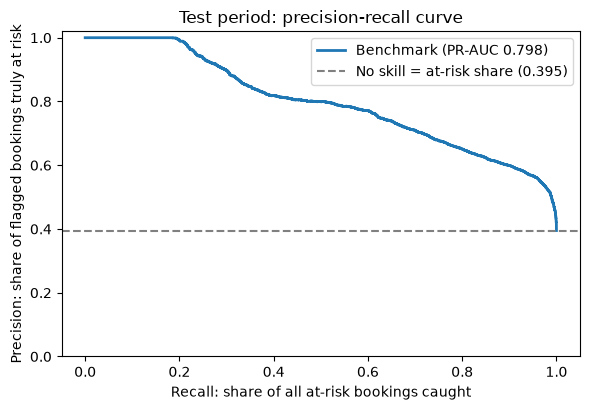

In [9]:
# --- the precision-recall curve behind the number
bt = results["benchmark_xgboost"]["test"]; y_t, s_t = bt["labels"], bt["scores"]
p, r, _ = precision_recall_curve(y_t, s_t)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(r, p, lw=2, label=f"Benchmark (PR-AUC {bt['pr_auc']:.3f})")
ax.axhline(y_t.mean(), ls="--", c="grey", label=f"No skill = at-risk share ({y_t.mean():.3f})")
ax.set_xlabel("Recall: share of all at-risk bookings caught"); ax.set_ylabel("Precision: share of flagged bookings truly at risk")
ax.set_title("Test period: precision-recall curve"); ax.set_ylim(0, 1.02); ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

## A6. Ablation: what does tuning add, and what do date features add?
The best single agent run in the study (a LightGBM model) beat the benchmark. A controlled ablation on the benchmark itself shows part of why. Only **one factor changes per step**:

| Variant | Hyper-parameters | Features |
|---|---|---|
| V1 | XGBoost defaults | the 24 inputs |
| V2 | **Optuna-tuned** (the benchmark) | the 24 inputs |
| V3 | XGBoost defaults | 24 + 7 date features |
| V4 | Optuna-tuned (*not* re-tuned) | 24 + 7 date features |

The date features come from columns already in the table (arrival year/month/day and lead time): week, weekday and month of arrival, weekday and month of the estimated booking date, and two running day counts. **No outcome column is used.**

,features,test PR-AUC,published,change vs V1
variant,,,,
"V1 defaults, 24 features",24,0.7939,0.7939,+0.0000
"V2 tuned, 24 features (= benchmark settings)",24,0.7977,0.7977,+0.0038
"V3 defaults, + date features",31,0.7991,0.7991,+0.0052
"V4 tuned, + date features",31,0.8070,0.8070,+0.0131


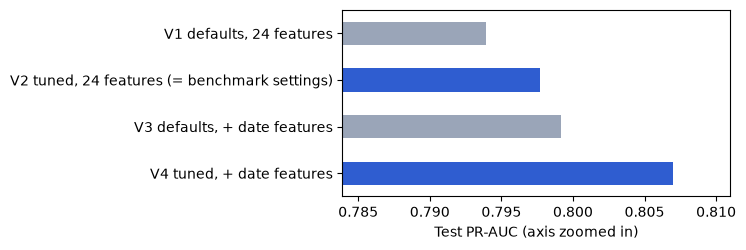

Reading it: tuning (V1 -> V2) and date features (V1 -> V3) each add a small amount, and both together (V4) add the most. These are single fits, so treat differences of about 0.001 as noise.


In [10]:
REF_DAY = pd.Timestamp("2015-01-01")
def add_date_features(Xc, raw_df):
    arr = C.arrival_date(raw_df); book = arr - pd.to_timedelta(Xc["lead_time"].astype(float).values, unit="D")
    out = Xc.copy()
    out["arrival_week"] = arr.dt.isocalendar().week.astype("float").values; out["arrival_dow"] = arr.dt.dayofweek.values; out["arrival_month"] = arr.dt.month.values
    out["booking_dow"] = book.dt.dayofweek.values; out["booking_month"] = book.dt.month.values
    out["arrival_day_count"] = (arr - REF_DAY).dt.days.values; out["booking_day_count"] = (book - REF_DAY).dt.days.values
    return out

# The study fitted the ablation variants on the de-duplicated training rows in FILE order (not date order), so we do the same here.
raw_u = train.drop_duplicates().reset_index(drop=True)
y_u = (raw_u["reservation_status"] != "Check-Out").astype(int).values
X_u = C.to_model_frame(C.clean(raw_u), levels)

# test set in the evaluator's order: one row per labelled booking (first occurrence of each booking_id)
test_raw = test_feat.drop_duplicates("booking_id").set_index("booking_id").reindex(test_lab["booking_id"]).reset_index()
y_test = test_lab["at_risk"].values.astype(int)
X_test24 = C.to_model_frame(C.clean(test_raw), levels)

rows = []
for name, tuned, dates in [("V1 defaults, 24 features", False, False), ("V2 tuned, 24 features (= benchmark settings)", True, False),
                           ("V3 defaults, + date features", False, True), ("V4 tuned, + date features", True, True)]:
    kw = dict(tree_method="hist", enable_categorical=True, random_state=SEED, n_jobs=THREADS); kw.update(study.best_params if tuned else {})
    Xtr, Xte = (add_date_features(X_u, raw_u), add_date_features(X_test24, test_raw)) if dates else (X_u, X_test24)
    m = xgb.XGBClassifier(**kw).fit(Xtr, y_u)
    rows.append({"variant": name, "features": Xtr.shape[1], "test PR-AUC": average_precision_score(y_test, m.predict_proba(Xte)[:, 1])})
abl = pd.DataFrame(rows).set_index("variant")
pub = pd.read_csv(ROOT / "results" / "published_ablation_benchmark.csv").set_index("variant")["test_pr_auc"].iloc[:4].values   # V1..V4 as published
abl["published"] = pub; abl["change vs V1"] = abl["test PR-AUC"] - abl.iloc[0]["test PR-AUC"]
display(abl.style.format({"test PR-AUC": "{:.4f}", "published": "{:.4f}", "change vs V1": "{:+.4f}"}))
ax = abl["test PR-AUC"].plot.barh(figsize=(7.5, 2.6), color=["#9aa5b8", "#2F5DD0", "#9aa5b8", "#2F5DD0"]); ax.invert_yaxis()
ax.set_xlim(abl["test PR-AUC"].min() - 0.01, abl["test PR-AUC"].max() + 0.004); ax.set_xlabel("Test PR-AUC (axis zoomed in)"); ax.set_ylabel(""); plt.tight_layout(); plt.show()
print("Reading it: tuning (V1 -> V2) and date features (V1 -> V3) each add a small amount, and both together (V4) add the most. These are single fits, so treat differences of about 0.001 as noise.")

## A7. Re-scoring saved agent deliverables
The folder `example_runs/` holds the real deliverables of three agent runs, exactly as the agents left them (`predict.py`, saved model, `notes.md`). We now score them with the **same evaluator** and compare with the published numbers in `published_metrics.json`.

| Run | Agent | Why it is interesting |
|---|---|---|
| **B38** | GPT Sol, high effort | the single best run of the study; a LightGBM model with hand-tried settings and date features |
| **B13** | Claude Haiku, high effort | the most token-hungry setting of the study |
| **B09** | GPT Luna, medium effort | a model that **relied on leaky columns**: look at the leak test |

In [11]:
example = {}
for run in ["B38", "B13", "B09"]:
    example[run] = evaluate(ROOT / "example_runs" / run, name=run)
rows = []
for run, res in example.items():
    pub = json.loads((ROOT / "example_runs" / run / "published_metrics.json").read_text())["test"]["pr_auc"]
    row = summary_row(res); row["published_test_PR_AUC"] = pub; row["difference"] = row["test_PR_AUC"] - pub; rows.append(row)
ex = pd.DataFrame(rows).set_index("name"); display(ex.style.format({"val_PR_AUC": "{:.4f}", "test_PR_AUC": "{:.4f}", "published_test_PR_AUC": "{:.4f}", "difference": "{:+.4f}"}))
lt = example["B09"]["leak_test"]
print(f"B09 leak test: validation PR-AUC {lt['pr_auc_full']:.4f} with leaky columns -> {lt['pr_auc_blanked']:.4f} when they are blanked (as in the test period)")
print("columns it relied on:", lt["columns_relied_on"], "| per-column drop:", {k: (round(v, 4) if v is not None else None) for k, v in lt["per_column_drop"].items()})

,status,val_PR_AUC,test_PR_AUC,test_95%_interval,leaky,relied_on,published_test_PR_AUC,difference
name,,,,,,,,
B38,ok,0.8815,0.8185,0.8106-0.8265,False,,0.8185,+0.0000
B13,ok,0.8510,0.7747,0.7652-0.7841,False,,0.7747,+0.0000
B09,ok,0.8786,0.7322,0.7226-0.7425,True,assigned_room_type|booking_changes,0.7322,+0.0000


B09 leak test: validation PR-AUC 0.8786 with leaky columns -> 0.8132 when they are blanked (as in the test period)
columns it relied on: ['assigned_room_type', 'booking_changes'] | per-column drop: {'reservation_status': 0.0, 'reservation_status_date': 0.0, 'is_canceled': 0.0, 'assigned_room_type': 0.0663, 'booking_changes': 0.0034}


In [12]:
# What did the best agent say about its own work? (first part of its notes.md)
print((ROOT / "example_runs" / "B38" / "notes.md").read_text()[:2200])

# Hotel booking cancellation-risk model

## Model and rationale

The saved estimator is a LightGBM gradient-boosted tree classifier (500 trees, learning rate 0.035, 23 leaves, minimum 100 rows per leaf, column fraction 0.9, L1 0.2, L2 1.0, random seed 42). LightGBM was chosen because it handles nonlinear effects, missing numeric values, and interactions between booking attributes efficiently. Its native categorical splits also avoid a large sparse feature matrix. The complete saved artifact is about 0.60 MB and scoring requires one model.

The positive class is `is_canceled` represented by `1`, `true`, or `Yes`; this agrees exactly with reservation outcomes Canceled and No-Show in the supplied tables. The final model and categorical encoder were fitted only on all 83,067 rows of `train`. The 17,730 later-period `validation` rows were used only for model/feature selection and reporting.

## Features available at booking creation

Raw numeric features:

- lead time
- arrival year, week n

## A8. The campaign results (54 hosted runs)
`results/campaign_review.csv` has one row per run (accuracy, tokens, minutes, list-price cost, leak test, audit status) and `results/cell_summary_2b.csv` the average of the three replicates of each *model and effort* setting. Token counts come from the Opik traces of the study (see Part B); they include cached input, so they are compared **within a vendor family only**. Costs are list-price equivalents because the runs used subscription logins.

The charts use the study's conventions: **tokens in thousands**, and effort shown by marker shape (circle = low, square = medium, triangle = high).

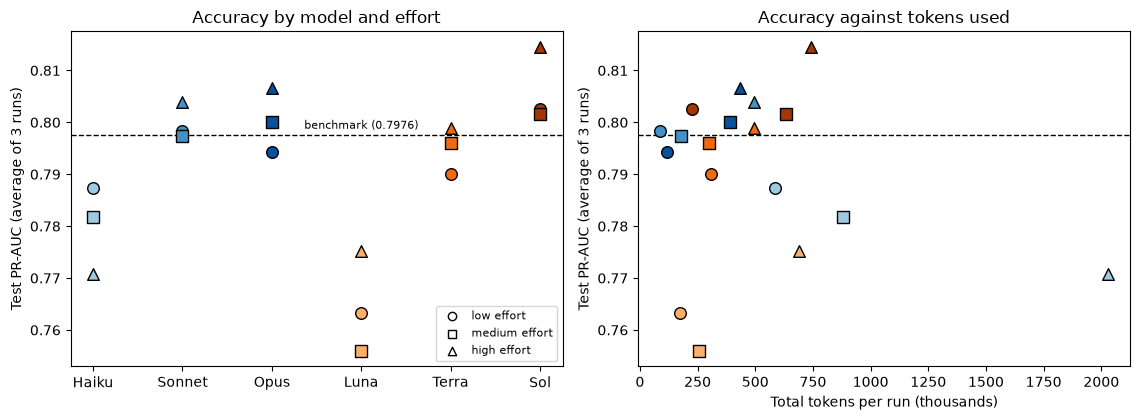

In [13]:
cs = pd.read_csv(ROOT / "results" / "cell_summary_2b.csv")
camp = pd.read_csv(ROOT / "results" / "campaign_review.csv")
MARK = {"low": "o", "medium": "s", "high": "^"}
models = ["Haiku", "Sonnet", "Opus", "Luna", "Terra", "Sol"]
colors = dict(zip(models, ["#9ecae1", "#4292c6", "#08519c", "#fdae6b", "#f16913", "#a63603"]))
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.3))
for m in models:
    for _, r in cs[cs.m == m].iterrows():
        axs[0].scatter(models.index(m), r["mean"], marker=MARK[r["effort"]], s=70, color=colors[m], edgecolor="k", zorder=3)
        axs[1].scatter(r["tokens"] / 1000, r["mean"], marker=MARK[r["effort"]], s=70, color=colors[m], edgecolor="k", zorder=3)
for ax in axs: ax.axhline(PUB_TEST_PR, ls="--", c="k", lw=1); ax.set_ylabel("Test PR-AUC (average of 3 runs)")
axs[0].set_xticks(range(6)); axs[0].set_xticklabels(models); axs[0].set_title("Accuracy by model and effort"); axs[0].text(3.0, PUB_TEST_PR + 0.0012, "benchmark (0.7976)", ha="center", fontsize=8)
axs[1].set_xlabel("Total tokens per run (thousands)"); axs[1].set_title("Accuracy against tokens used")
for k, mk in MARK.items(): axs[0].scatter([], [], marker=mk, color="white", edgecolor="k", label=k + " effort")
axs[0].legend(loc="lower right", fontsize=8); plt.tight_layout(); plt.show()

In [14]:
# Judgement traps: how often did each model fall into them? (3 efforts x 3 replicates = 9 runs per model)
traps = camp.groupby("model").agg(runs=("run_id", "count"), relied_on_leaky_column=("leaky", "sum"), avg_test_PR_AUC=("test_pr_auc", "mean"),
                                  avg_tokens_k=("total_tokens", lambda s: s.mean() / 1000), avg_minutes=("wall_min", "mean"), avg_cost_usd=("cost_usd", "mean"))
display(traps.round(3))
print("Hypothesis scorecard (decision rules were written before the runs):")
display(pd.read_csv(ROOT / "results" / "hypothesis_scorecard_2b.csv")[["id", "verdict"]].T)

,runs,relied_on_leaky_column,avg_test_PR_AUC,avg_tokens_k,avg_minutes,avg_cost_usd
model,,,,,,
Claude Haiku 5.5,9,0,0.780,1163.287,4.870,0.038
Claude Opus 5.5,9,0,0.800,313.367,3.653,0.479
Claude Sonnet 5.5,9,2,0.800,254.105,2.329,0.192
GPT-5.6 Luna,9,9,0.765,374.976,5.176,0.025
GPT-5.6 Sol,9,0,0.806,534.284,6.852,0.560
GPT-5.6 Terra,9,1,0.795,366.296,5.513,0.249


Hypothesis scorecard (decision rules were written before the runs):


,0,1,2,3,4,5,6,7
id,H1,H2,H3,H4,H5,H6,H7,H8
verdict,partly supported,not supported,not supported,partly supported,not supported,supported,supported,supported


## A9. Part A summary
* The data is split by **time**; the hidden test period is genuinely later than anything an agent saw.
* The benchmark (Optuna-tuned XGBoost) scores about **0.80 PR-AUC** against a no-skill floor of **0.395**; tuning and date features each add a small, measurable amount.
* The evaluator scores every entrant identically, and its **leak test** exposes models that depend on columns that will not exist in production.
* The saved agent deliverables re-score to their published numbers, and the campaign tables show how accuracy, tokens, time and cost vary with model and effort.

*Findings are descriptive: with three replicates per setting this is not a statistical significance test.*

---
# Part B. Replicating the agent experiment
Part A used the *outputs* of the experiment. Part B shows **how the agents were run**, and lets you run one yourself.

**Be aware:** a real run uses an LLM through your own account. In the study a run took 4-40 minutes and used 90 thousand to over 2 million tokens, i.e. roughly $0.05 to $2 at list prices. The cell that launches an agent is switched off by default (`RUN_AGENT = False`).

## B1. The tools
| Tool | Role |
|---|---|
| **[Hermes Agent](https://hermes-agent.nousresearch.com/docs)** (open source) | the agent framework: gives a model a terminal and file tools, runs the plan-code-run loop; one profile per model, memory switched off |
| **Opik** (Comet) | traces every model call (tokens, timing, cost); used in the study to count tokens per run. Optional for you |
| `src/harness.py` | this repository's portable harness: run folders, command builder, time limit, rule auditor |
| `src/evaluator.py` | the independent scorer you used in Part A |

## B2. The brief, budgets and rules
Every agent got **one identical, unguided brief**: the business purpose, the deliverable and how it is judged (accuracy first, then time/compute/cost, then rule compliance). It gives **no method advice** and **does not mention** leaky columns or duplicates; noticing them is the test of judgement. The exact text is frozen: its SHA-256 hash must match `agent_harness/approved_brief.sha256`.

In [15]:
import harness as H
print("brief approved (hash matches):", H.brief_is_approved(), "\n")
print((ROOT / "agent_harness" / "brief_unguided.md").read_text())

brief approved (hash matches): True 

# Task: predict hotel booking cancellation risk

You are a data scientist working alone, in the current directory. A hotel group in Singapore (City Hotel and Airport Hotel) wants to know, **at the moment a booking is created**, how likely that booking is to end in a **cancellation or no-show** ("at risk"). Revenue staff will use your score to decide on overbooking, deposit reminders and inventory. Build a model that scores new bookings, and deliver it as described below.

## Data
* `./train_val.db` is a read-only SQLite file with two tables: `train` and `validation`. Validation covers a later period than train (rows are not sorted). Every column is stored as text, and the formatting is raw and messy; you must inspect and clean it yourself.
* Your model will be judged on a hidden **future** test period that you cannot see.
* Positive class = at risk (the booking ended as Canceled or No-Show). The other outcome is Check-Out.

## What to deliver (fold

In [16]:
print("Budgets applied to every run:"); print(json.dumps({k: v for k, v in H.BUDGETS.items() if k != "status"}, indent=1))

Budgets applied to every run:
{
 "wall_clock_min": 45,
 "command_min": 10,
 "compute_min": 10,
 "optuna_trials": 60,
 "threads": 8,
 "max_turns": 100
}


## B3. The run plan
The study had **6 hosted models x 3 effort levels x 3 replicates = 54 runs** (plus 6 local Gemma runs). The order was randomised in **three blocks** (each block holds every model-and-effort setting once, fixed seed) and runs were executed **one at a time**, so time of day, rate limits or provider drift cannot line up with one model.

In [17]:
plan = pd.DataFrame(H.PLAN)
display(plan.groupby(["family", "model_label", "setting"]).size().unstack("setting").fillna(0).astype(int))
print("First six runs of the randomised order:")
display(plan[["order", "run_id", "block", "model_label", "setting", "provider"]].head(6))

setting                      high  low  medium  think-off  think-on
family    model_label                                              
Anthropic Claude Haiku 5.5      3    3       3          0         0
          Claude Opus 5.5       3    3       3          0         0
          Claude Sonnet 5.5     3    3       3          0         0
Local     Gemma 4 e4b           0    0       0          3         3
OpenAI    GPT-5.6 Luna          3    3       3          0         0
          GPT-5.6 Sol           3    3       3          0         0
          GPT-5.6 Terra         3    3       3          0         0

First six runs of the randomised order:


,order,run_id,block,model_label,setting,provider
0,1,B01,1,GPT-5.6 Terra,medium,openai-codex
1,2,B02,1,GPT-5.6 Terra,low,openai-codex
2,3,B03,1,Claude Sonnet 5.5,medium,anthropic
3,4,B04,1,GPT-5.6 Luna,low,openai-codex
4,5,B05,1,Claude Sonnet 5.5,high,anthropic
5,6,B06,1,Claude Opus 5.5,medium,anthropic


## B4. Prepare an isolated run folder
Each run gets its **own folder**, its **own virtual environment** and a **read-only copy of `train_val.db`**. The hidden test data (`data/test.db`) is **never** copied into it; only the evaluator reads that file.
This cell builds a demonstration folder without installing a virtual environment (set `install_requirements=True`, which needs [`uv`](https://docs.astral.sh/uv/), for a real run).

In [18]:
demo_base = OUT / "demo_runs"
shutil.rmtree(demo_base, ignore_errors=True)
work = H.prepare_run_folder("DEMO01", base=demo_base, install_requirements=False)
print("run folder contents:", sorted(p.name for p in work.iterdir()))
print("train_val.db read-only:", not os.access(work / "train_val.db", os.W_OK), "| test data present in run folder:", (work / "test.db").exists())

run folder contents: ['train_val.db']
train_val.db read-only: True | test data present in run folder: False


## B5. Launch an agent (optional)
`build_agent_command` assembles the Hermes command for one row of the plan: the model, the provider, the reasoning effort, the 100-turn cap and the brief as the single user message. `run_agent` starts it with a hard 45-minute wall-clock limit.

To run one for real:
1. Install Hermes and create a profile with **memory switched off** (see the [documentation](https://hermes-agent.nousresearch.com/docs)); log in to the provider you want.
2. Pick a row of `H.PLAN` whose provider you have, set `PROFILE` to your profile name, and set `RUN_AGENT = True`.
3. Use `install_requirements=True` so the agent gets a clean environment.

In [19]:
RUN_AGENT = False                       # <- switch to True only if you accept the cost
PROFILE = "YOUR_HERMES_PROFILE"         # <- your Hermes profile name
row = H.PLAN[0]                         # <- choose any row of the plan
cmd = H.build_agent_command(row, work, profile=PROFILE)
print("Command that would be run:\n ", " ".join(cmd).replace(str(ROOT) + "/", ""))
if RUN_AGENT:
    live = H.prepare_run_folder("MYRUN01", base=OUT / "my_runs", install_requirements=True)
    code_, minutes, timed_out = H.run_agent(H.build_agent_command(row, live, profile=PROFILE), live)
    print(f"agent exited with code {code_} after {minutes} min (hit the time limit: {timed_out})")
else:
    print("\nRUN_AGENT is False: nothing was launched.")

Command that would be run:
  hermes -p YOUR_HERMES_PROFILE chat -Q -m gpt-5.6-terra --provider openai-codex --reasoning medium --max-turns 100 --in outputs/demo_runs/DEMO01/work --query-file agent_harness/brief_unguided.md

RUN_AGENT is False: nothing was launched.


## B6. Score the run and audit the rules
When the agent finishes, its `deliverable/` folder is scored by the **same evaluator** as in Part A. The rule auditor then scans the agent's terminal commands. In the study a **confirmed violation made the run invalid** (it was counted, not rerun); reading the *validation* data or writing scratch files was fine.

In [20]:
deliverable = OUT / "my_runs" / "MYRUN01" / "work" / "deliverable"
if (deliverable / "predict.py").exists():
    res = evaluate(deliverable, name="MYRUN01"); display(pd.DataFrame([summary_row(res)]))
else:
    print("No agent deliverable yet (Part B ran without launching an agent). Showing the auditor on example commands instead:")
examples = ["./.venv/bin/python train.py", "ls ../test_holdout", "hermes chat -q 'solve this for me'", "python3 -c 'print(1)'",
            "uv pip install --python ./.venv/bin/python lightgbm", "pip install shap"]
flagged = H.scan_commands(examples)
for c, rule in flagged: print(f"VIOLATION [{rule}]: {c}")
print("clean commands:", [c for c in examples if c not in {c for c, _ in flagged}])

No agent deliverable yet (Part B ran without launching an agent). Showing the auditor on example commands instead:
VIOLATION [touches_test_data]: ls ../test_holdout
VIOLATION [starts_another_model]: hermes chat -q 'solve this for me'
VIOLATION [inline_interpreter]: python3 -c 'print(1)'
VIOLATION [installs_globally]: pip install shap
clean commands: ['./.venv/bin/python train.py', 'uv pip install --python ./.venv/bin/python lightgbm']


## B7. Extending the study, and limitations
* **Other models or efforts:** add rows to `agent_harness/run_plan.json` (model id, provider, setting). Keep the brief and budgets unchanged if you want comparable results.
* **Other tasks:** replace `train_val.db`, the brief and the evaluator's label; the harness, run folders and leak-test logic carry over.
* **Replicates:** agent runs are not deterministic. The study used three replicates per setting and reports spread, not significance.

**Limitations to keep in mind:** one dataset and one task; three replicates per setting; token counts differ between vendors because of caching, so they are compared within a family; costs are list-price equivalents; the local Gemma runs produced no scoreable model.